# Conservative Interpolants

On a finite-volume grid the data are averages, not point values.

An interpolating polynomial through the cell centres would ignore that. A *conservative interpolant* is a polynomial that, when averaged back over each cell, returns the average stored there.

We use the notation of the lectures: $u$ is the state and $u_i$ is its average over cell $i$.

## Quadratic polynomial:

We want to construct a quadratic polynomial through the points $x_{i-1}$, $x_i$, $x_{i+1}$ that gives the correct averages, $u_{i-1}$, $u_i$ and $u_{i+1}$ when integrated over the volume, e.g.

$$\frac{1}{\Delta x} \int_{x_{i-1/2}}^{x_{i+1/2}} u(x)\, dx = u_i$$

There are 3 unknowns in the quadratic and three constraints, so this is a linear system we can solve.

**Reference**: M. Zingale, *Introduction to Computational Astrophysical Hydrodynamics*, Section 3.3, Exercise 3.2.

In [1]:
# Importing libraries
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

# To see the outputs in latex format, we use:
from sympy.interactive import printing
printing.init_printing(use_latex = True)

In [2]:
# Define symbols

A, B, C, x, x0 = sp.symbols("A B C x x0")

# Quadratic equation
u_poly = A*(x - x0)**2 + B*(x - x0) + C

display(u_poly)

In [3]:
# Define symbol for delta_x

dx = sp.symbols(r"\Delta")

display(dx)

The three constraints are the averages over the cells $i-1$, $i$ and
$i+1$. Their edges sit at $x_i \pm \Delta x/2$ and $x_i \pm 3\Delta x/2$:

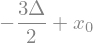

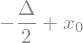

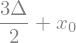

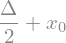

In [4]:
# Constraints:

# ul-> <u>_{i-1}
# u0-> <u>_{i}
# ur-> <u>_{i+1}

ul, u0, ur = sp.symbols("u_{i-1} u_i u_{i+1}")

# Fractions for the left borders
xl_32 = x0 - sp.Rational(3,2)*dx
xl_12 = x0 - sp.Rational(1,2)*dx

# Fractions for the right borders
xr_32 = x0 + sp.Rational(3,2)*dx
xr_12 = x0 + sp.Rational(1,2)*dx

# Print the result
display(xl_32, xl_12, xr_32, xr_12)

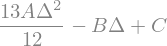

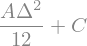

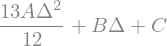

In [5]:
# Integrate

a = sp.simplify(sp.integrate(u_poly/dx, (x, xl_32, xl_12)))
b = sp.simplify(sp.integrate(u_poly/dx, (x, xl_12, xr_12)))
c = sp.simplify(sp.integrate(u_poly/dx, (x, xr_12, xr_32)))

display(a, b, c)

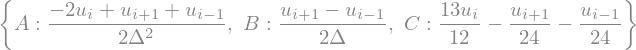

In [6]:
# Find the coefficients of the polynomial

coef_poly = sp.solve([a - ul, b - u0, c - ur], [A, B, C])

display(coef_poly)

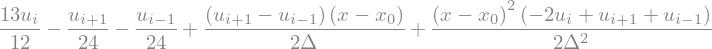

In [7]:
u_quad = u_poly.subs(A, coef_poly[A]).subs(B, coef_poly[B])               .subs(C, coef_poly[C])

display(u_quad)

**Notes:**

The quadratic coefficient is the usual second difference and the linear coefficient is the usual centred difference. The constant term is the
interesting one: it is not $u_i$, but

$$\frac{-u_{i-1} + 26 u_i - u_{i+1}}{24}$$

So the interpolant does not pass through the cell average at the cell centre.

That correction is exactly what makes the three cell averages come out right, and it is the difference between an accurate interpolant and a
conservative one.

## Colella and Woodward PPM interpolator:

### Cubic

We want to construct a cubic polynomial through the points $x_{i-2}$,
$x_{i-1}$, $x_i$, $x_{i+1}$ that gives the correct averages, $u_{i-2}$,
$u_{i-1}$, $u_i$ and $u_{i+1}$ when integrated over the volume of each
zone.

In [8]:
A, B, C, D = sp.symbols("A B C D")

u_poly = A*(x - x0)**3 + B*(x - x0)**2 + C*(x - x0) + D

display(u_poly)

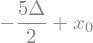

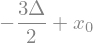

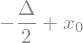

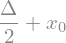

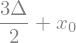

In [9]:
# Constraints:

ull, ul, u0, ur = sp.symbols("u_{i-2} u_{i-1} u_i u_{i+1}")

xl_52 = x0 - sp.Rational(5,2)*dx
xl_32 = x0 - sp.Rational(3,2)*dx
xl_12 = x0 - sp.Rational(1,2)*dx

xr_12 = x0 + sp.Rational(1,2)*dx
xr_32 = x0 + sp.Rational(3,2)*dx

display(xl_52, xl_32, xl_12, xr_12, xr_32)

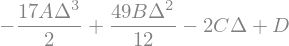

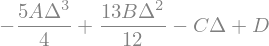

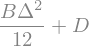

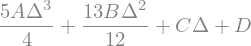

In [10]:
# Integrate

a = sp.simplify(sp.integrate(u_poly/dx, (x, xl_52, xl_32)))
b = sp.simplify(sp.integrate(u_poly/dx, (x, xl_32, xl_12)))
c = sp.simplify(sp.integrate(u_poly/dx, (x, xl_12, xr_12)))
d = sp.simplify(sp.integrate(u_poly/dx, (x, xr_12, xr_32)))

display(a, b, c, d)

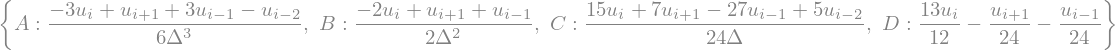

In [11]:
# Find the coefficients of the polynomial

coef_poly = sp.solve([a - ull, b - ul, c - u0, d - ur], [A, B, C, D])

display(coef_poly)

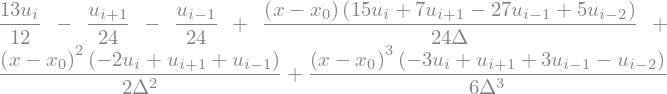

In [12]:
u_poly3 = u_poly.subs(A, coef_poly[A]).subs(B, coef_poly[B])\
                .subs(C, coef_poly[C]).subs(D, coef_poly[D])

display(u_poly3)

This interpolant is symmetric about the $i-\frac{1}{2}$ interface:

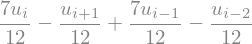

In [13]:
u_poly3.subs(x, x0 - sp.Rational(1,2)*dx)

This is the interpolating polynomial used to find the interface states in PPM (Colella & Woodward 1984).

### Reference paper:

https://www.sciencedirect.com/science/article/abs/pii/0021999184901438?via%3Dihub

## Check: does the quadratic really conserve?

We take a function we know, compute its 3 cell averages by exact integration, feed them to the interpolant above, and average the
interpolant back over each cell. The two sets of numbers must agree.

In [14]:
# A test function and a grid spacing
g = sp.sin(x)

# Delta x
h = sp.Rational(1, 2)

# x_i       
xi = sp.Rational(1, 1)      

# Exact cell averages of g over the three cells
edges = [xi - 5*h/2, xi - 3*h/2, xi - h/2, xi + h/2, xi + 3*h/2]
av = [sp.integrate(g, (x, edges[k+1], edges[k+2]))/h for k in range(3)]

for k, label in enumerate(("<g>_{i-1}", "<g>_{i}", "<g>_{i+1}")):
    print("%-12s %.10f" % (label, float(av[k])))

<g>_{i-1}    0.4744471057
<g>_{i}      0.8327330130
<g>_{i+1}    0.9871368361


In [15]:
# Build the quadratic interpolant from those three averages
u_check = u_quad.subs({ul: av[0], u0: av[1], ur: av[2], dx: h, x0: xi})

# Average the interpolant back over each cell
for k, label in enumerate(("<u>_{i-1}", "<u>_{i}", "<u>_{i+1}")):
    back = sp.integrate(u_check, (x, edges[k+1], edges[k+2]))/h
    print("%-12s %.10f   (error %.2e)"
          % (label, float(back), float(back - av[k])))

<u>_{i-1}    0.4744471057   (error 0.00e+00)
<u>_{i}      0.8327330130   (error 0.00e+00)
<u>_{i+1}    0.9871368361   (error 0.00e+00)


In [16]:
# Numerical version of the same picture
u_num = sp.lambdify(x, u_check, "numpy")
xs = np.linspace(float(edges[1]), float(edges[4]), 400)

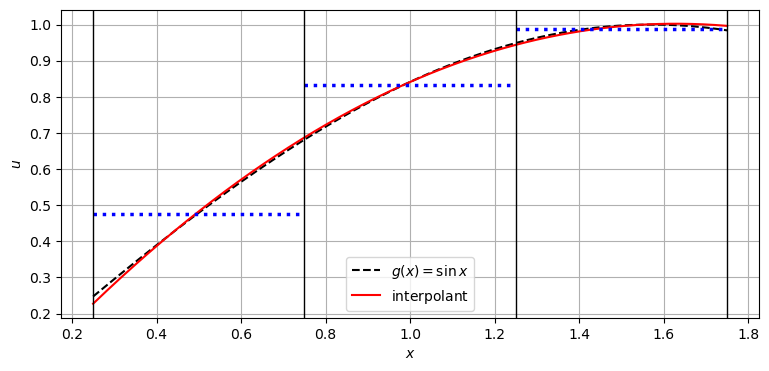

In [17]:
plt.figure(figsize=(9,4))

plt.plot(xs, np.sin(xs), color = "black", linestyle = "--",
         label = r"$g(x) = \sin x$")
plt.plot(xs, u_num(xs), color = "red", label = r"${\rm interpolant}$")

for k in range(3):
    xa, xb = float(edges[k+1]), float(edges[k+2])
    plt.plot([xa, xb], [float(av[k]), float(av[k])], color = "blue",
             linestyle = ":", linewidth = 2.5)
    plt.axvline(xa, color = "black", linewidth = 1.0)
plt.axvline(float(edges[4]), color = "black", linewidth = 1.0)

plt.xlabel(r"$x$")
plt.ylabel(r"$u$")
plt.grid()
plt.legend()
plt.show()

### Observations:

The interpolant reproduces the three cell averages to machine precision, and it tracks the original function closely inside the three cells. 

- The dotted grey lines are the averages

- The red curve crosses each of them twice.

Away from the three cells the quadratic drifts, which is why a finite-volume code builds a new interpolant in every cell instead of one polynomial for the whole grid.